# What comes after five songs?
### Spotify playlist continuation with track history, artist identity, and audio similarity

Given five consecutive tracks in a curated playlist, rank the catalog for the track in the sixth position. The central experiment measures the change in retrieval quality when a model that already knows playlist history and artist identity gains access to audio descriptors.

**Result in this sample.** Artist identity explains most of the top-ten retrieval gain. A last-artist rule recovers 23 of 100 sixth songs. A learned ranker using history and artist recovers 24, and adding audio also recovers 24. Audio changes *which* songs surface and improves the median rank of unseen targets. The practical conclusion depends on how many recommendations a listener will actually see.

**Reading the notebook.** Sections 1–5 follow the assignment rubric. All numbers and figures below are produced by the displayed code. The HTML export includes the results. To rerun, put `songs620.csv` beside this notebook, or set `SONGS620_PATH` to its location. A Desktop copy is also recognized.

[1 · Task](#part-1)　[2 · Data](#part-2)　[3 · Models](#part-3)　[4 · Evaluation](#part-4)　[5 · Findings](#part-5)

<a id="part-1"></a>

## 1 · Predictive task and validity criteria

**Observation and target.** Each test playlist supplies one opening query. Positions 0–4 are visible. Position 5 supplies the single observed target. A playlist curator's ordering supplies the label. Playback, skips, user satisfaction and other plausible continuations are unobserved.

**Prediction setting.** A recommender can look up track IDs, artist IDs and static audio features for the entire snapshot catalog, including newly encountered songs. Playlist membership, track popularity and transitions must come from the training playlists. This is a *known-catalog, new-playlist* experiment. Treating every song in the file as available at once is an explicit assumption because release and playlist creation times are unavailable. Previously played tracks remain eligible because curators can repeat them.

**Primary comparison.** Compare the same logistic ranking model with and without audio, with artist features in both. The primary endpoint is **Hit Rate@10**, the fraction of opening queries with the exact target in the top ten. **MRR@10** averages reciprocal target rank for top-ten hits and zero otherwise. We also report the target's median rank to see movement below the cutoff. The full catalog competes on every query. Baselines include uniform random ranking in expectation, popularity, item–item cosine similarity, a first-order Markov model, and audio similarity.

**Validation plan.** Split playlist IDs 80/10/10 before constructing windows. Choose regularization on validation openings. Freeze the models and evaluate test openings once. Report results by zero versus positive training support, a paired playlist-bootstrap interval for the primary difference, and two sensitivity checks for prefix order and position. The seed-42 split was used in the planning discussion to check catalog coverage. Its coverage is known in advance. Model performance was not used to choose the split.

In [1]:
from pathlib import Path
import os, sys, hashlib, random, platform
from collections import Counter
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown
%matplotlib inline
plt.rcParams.update({'figure.dpi': 115, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': False, 'axes.titlelocation': 'left', 'font.size': 10})
TEAL, BLUE, ORANGE = '#087e75', '#324b70', '#bd6329'
pd.options.display.float_format = '{:,.4f}'.format
def report(text):
    display(Markdown(text))

paths = [Path('songs620.csv'), Path.home() / 'Desktop' / 'songs620.csv']
if os.getenv('SONGS620_PATH'):
    paths.insert(0, Path(os.environ['SONGS620_PATH']).expanduser())
path = next((p for p in paths if p.is_file()), None)
if path is None:
    raise FileNotFoundError('Place songs620.csv beside the notebook or set SONGS620_PATH.')
digest = hashlib.sha256(path.read_bytes()).hexdigest()
assert digest == '11533e4997668e7791c093bbcc63fb20ed820e8c4bbd80b7026fedaf1fb8d946', 'Input differs from the audited release.'
df = pd.read_csv(path).sort_values(['pid', 'pos']).reset_index(drop=True)
print(f'Input: {path.name}  |  SHA-256: {digest}')
print('Python', platform.python_version(), '|', ', '.join(f'{p} {version(p)}' for p in ['numpy','pandas','scipy','scikit-learn','matplotlib']))

Input: songs620.csv  |  SHA-256: 11533e4997668e7791c093bbcc63fb20ed820e8c4bbd80b7026fedaf1fb8d946
Python 3.14.0 | numpy 2.4.1, pandas 3.0.0, scipy 1.17.0, scikit-learn 1.8.0, matplotlib 3.11.0


<a id="part-2"></a>

## 2 · Data collection, preparation, and exploration

The upstream Spotify Million Playlist Dataset samples public, user-created US playlists from 2010–2017. Its authors describe filtering and perturbation during release. The supplied CSV is one enriched slice published by AC209A Group 137, who retrieved track audio features through Spotify's API. A row represents one occurrence of a recording in a playlist. The sampling frame limits generalization to today's catalog, private playlists and live listening sessions. [Spotify dataset introduction](https://engineering.atspotify.com/2018/05/introducing-the-million-playlist-dataset-and-recsys-challenge-2018) · [Enrichment method](https://suton5.github.io/recsys137/) · [Source CSV](https://github.com/suton5/recsys137/blob/master/test_data/songs620.csv)

Group by recording URI because track names can collide. Check for contiguous ordering, missing data, conflicting metadata, repeated positions and duplicate playlists. Repeated recordings at different positions represent valid transitions. The unused CSV index, URLs, track names and album names play no part in fitting the model.

In [2]:
audio_cols = ['danceability','energy','loudness','speechiness','acousticness','instrumentalness',
              'liveness','valence','tempo','duration_ms']
static = ['artist_uri'] + audio_cols
assert not df[['pid','pos','track_uri'] + static].isna().any().any()
assert df.track_uri.eq(df.uri).all() and df.track_uri.eq('spotify:track:' + df.id).all()
assert np.isfinite(df[audio_cols].to_numpy()).all()
assert df.groupby('pid').cumcount().eq(df.pos).all()
assert df.groupby('track_uri')[static].nunique().le(1).all().all()
catalog = df.drop_duplicates('track_uri').set_index('track_uri').sort_index()
df['song'] = catalog.index.get_indexer(df.track_uri)
lists = {int(pid): g.song.to_numpy() for pid, g in df.groupby('pid')}
assert len({tuple(s) for s in lists.values()}) == len(lists)
ids = sorted(lists)
random.Random(42).shuffle(ids)
train, val, test = ids[:800], ids[800:900], ids[900:]
assert len(ids) == 1000 and not (set(train)&set(val) or set(train)&set(test) or set(val)&set(test))
N = len(catalog)
items = np.arange(N)
artist = pd.factorize(catalog.artist_uri)[0]
tracks = catalog.track_name.to_numpy()
artists = catalog.artist_name.to_numpy()
train_frame = df[df.pid.isin(train)]
freq = train_frame.groupby('song').pid.nunique().reindex(items,fill_value=0).to_numpy()
sizes = np.array([len(lists[i]) for i in train])
display(pd.DataFrame([{
    'Playlists': len(lists), 'Occurrences': len(df), 'Distinct recordings': N,
    'Extra appearances within a playlist': int(df.duplicated(['pid','song']).sum()),
    'Missing input cells': int(df.isna().sum().sum()),
    'Duplicate (playlist, position)': int(df.duplicated(['pid','pos']).sum())
}]))
display(pd.DataFrame([{'Split': name, 'Playlists': len(group), 'Occurrences': sum(len(lists[i]) for i in group),
                       'Eligible openings': sum(len(lists[i]) >= 6 for i in group)}
                      for name,group in [('Train',train),('Validation',val),('Test',test)]]).set_index('Split'))

,Playlists,Occurrences,Distinct recordings,Extra appearances within a playlist,Missing input cells,"Duplicate (playlist, position)"
0,1000,66263,36203,854,0,0


,Playlists,Occurrences,Eligible openings
Split,,,
Train,800,53534,793
Validation,100,6012,100
Test,100,6717,100


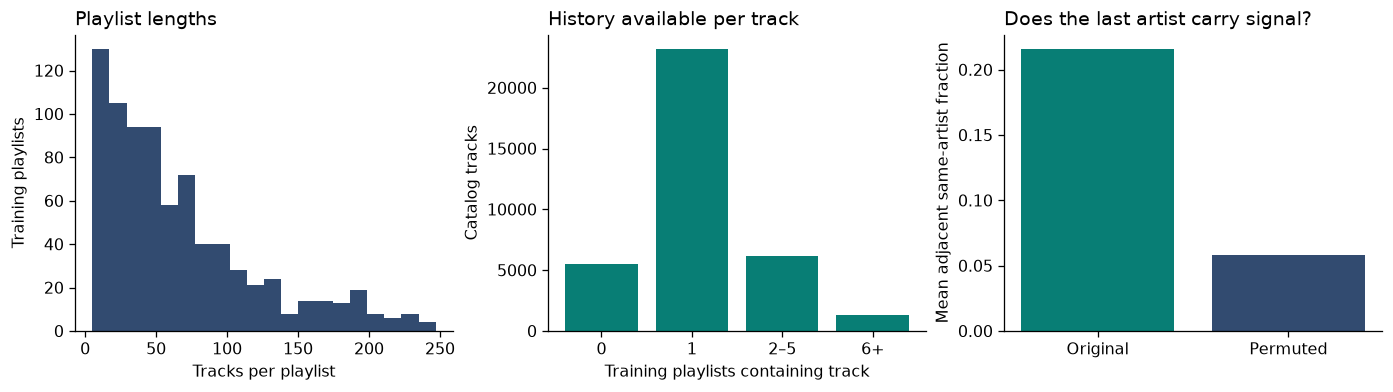

The median training playlist has **50 tracks**. **23,197** catalog tracks occur in exactly one training playlist and **5,470** in none. Adjacent tracks share an artist on average **21.6%** of the time, versus **5.8%** after a within-playlist permutation. Each playlist has equal weight in this descriptive check. The comparison motivates including artist identity when testing audio.

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(12,3.3), layout='constrained')
ax[0].hist(sizes, bins=20, color=BLUE)
ax[0].set(xlabel='Tracks per playlist', ylabel='Training playlists', title='Playlist lengths')
support_bins = [sum(freq==0),sum(freq==1),sum((freq>=2)&(freq<=5)),sum(freq>=6)]
ax[1].bar(['0','1','2–5','6+'], support_bins, color=TEAL)
ax[1].set(xlabel='Training playlists containing track',ylabel='Catalog tracks',title='History available per track')
# Within-playlist permutation preserves artist composition and playlist length.
shuffle_rng = np.random.default_rng(414)
real, shuffled = [], []
for pid in train:
    a = artist[lists[pid]]
    perm = shuffle_rng.permutation(a)
    real.append((a[1:] == a[:-1]).mean())
    shuffled.append((perm[1:] == perm[:-1]).mean())
ax[2].bar(['Original','Permuted'], [np.mean(real),np.mean(shuffled)], color=[TEAL,BLUE])
ax[2].set(ylabel='Mean adjacent same-artist fraction',title='Does the last artist carry signal?')
plt.show()
report(f"The median training playlist has **{np.median(sizes):.0f} tracks**. **{(freq==1).sum():,}** catalog tracks occur in exactly one training playlist and **{(freq==0).sum():,}** in none. Adjacent tracks share an artist on average **{np.mean(real):.1%}** of the time, versus **{np.mean(shuffled):.1%}** after a within-playlist permutation. Each playlist has equal weight in this descriptive check. The comparison motivates including artist identity when testing audio.")

<a id="part-3"></a>

## 3 · Models and fitting

For each track *i*, let nᵢ count its training playlists. Popularity ranks by this count. Item–item cosine divides the number of training playlists shared by two tracks by the geometric mean of their individual counts. Average this similarity over the five seed tracks. The transition model counts how many times the last seed track was immediately followed by each candidate. For a fixed predecessor, sorting these counts is equivalent to sorting conditional transition probabilities. Ties in these two history baselines fall back to training popularity. Any remaining ties use a fixed random ordering independent of interactions.

The audio baseline ranks by distance from the centroid of the five seed songs. Each audio dimension is standardized using distinct training tracks. Duration and tempo use a log transform, with zero tempo treated as unknown and imputed from training tracks. The selected descriptors are continuous. Musical key and mode would require a separate encoding. Squared Euclidean distance is cheap and interpretable, although correlated descriptors such as energy and loudness can count overlapping information twice.

The learned rankers use a regularized logistic classifier on *prefix, candidate* pairs. The positive is the observed next track. Uniformly sampled alternatives serve as negatives for that particular position. Its decision score ranks tracks. Negative sampling changes the intercept, so these scores are interpreted only as relative preferences. The nested feature sets isolate the effects of artist and audio information. All three use the same training pairs, fitting procedure and regularization grid.

In [4]:
features = ['Log playlist count','Mean seed cosine','Log next-track count',
            'Same last artist','Seed artist share','Audio to centroid','Audio to last']
specs = {'History LR': 3, 'History + artist LR': 5, 'History + artist + audio LR': 7}
catalog_audio = catalog[audio_cols].to_numpy(dtype=float, copy=True)
for col in ['tempo','duration_ms']:
    j = audio_cols.index(col)
    catalog_audio[:,j] = np.log(np.where(catalog_audio[:,j] > 0, catalog_audio[:,j], np.nan))

def build_reference(pids):
    seq = [lists[i] for i in pids]
    rr = np.repeat(np.arange(len(seq)), [len(s) for s in seq])
    cc = np.concatenate(seq)
    membership = sparse.coo_matrix((np.ones(len(cc)),(rr,cc)),shape=(len(seq),N)).tocsc()
    membership.data[:] = 1  # one vote per playlist even if a song repeats
    support = np.asarray(membership.sum(axis=0)).ravel()
    invnorm = 1 / np.sqrt(np.maximum(support,1))
    prev = np.concatenate([s[:-1] for s in seq])
    nxt = np.concatenate([s[1:] for s in seq])
    trans = sparse.coo_matrix((np.ones(len(prev)),(prev,nxt)),shape=(N,N)).tocsr()
    hist = support > 0
    med = np.nanmedian(catalog_audio[hist],axis=0)
    cleaned = np.where(np.isfinite(catalog_audio),catalog_audio,med)
    z = StandardScaler().fit(cleaned[hist]).transform(cleaned)
    return dict(B=membership, n=support, inv=invnorm, T=trans, z=z, norm2=(z*z).sum(axis=1))

def design(ref, prefix, cand):
    B, inv = ref['B'], ref['inv']
    playlist_weights = B[:,prefix] @ (inv[prefix] / len(prefix))
    cos = (B.T @ playlist_weights)[cand] * inv[cand]
    tr = ref['T'].getrow(prefix[-1]).toarray().ravel()[cand]
    za = ref['z']
    a = za if cand is items else za[cand]
    def audio_score(query):
        # Negative mean squared standardized distance. Larger means closer.
        return -(ref['norm2'][cand] - 2*(a @ query) + query @ query) / a.shape[1]
    matches = artist[cand,None] == artist[prefix][None,:]
    return np.column_stack([np.log1p(ref['n'][cand]), cos, np.log1p(tr),
        matches[:,-1], matches.mean(axis=1), audio_score(za[prefix].mean(axis=0)),
        audio_score(za[prefix[-1]])])

def windows(pids, *, openings=False, cap=None):
    for pid in pids:
        s = lists[pid]
        starts = np.arange(0, len(s)-5, 6)  # non-overlapping six-track windows
        if openings:
            starts = starts[:1]
        elif cap and len(starts)>cap:
            starts = starts[np.linspace(0,len(starts)-1,cap,dtype=int)]
        for k in starts:
            yield pid, int(k), s[k:k+5], s[k+5]

# Verify sparse implementation on an actual training transition using direct counts.
ref = build_reference(train)
pid, _, q, y = next(windows(train,openings=True))
trial = design(ref,q,np.array([y]))[0]
seq_sets = [set(lists[p]) for p in train]
direct = np.mean([sum(t in s and y in s for s in seq_sets) /
                  np.sqrt(max(freq[t],1)*max(freq[y],1)) for t in q])
assert np.isclose(trial[1],direct)
assert np.isclose(np.expm1(trial[2]),sum(((lists[p][:-1]==q[-1]) & (lists[p][1:]==y)).sum() for p in train))
assert np.isclose(trial[5],-np.mean((ref['z'][y]-ref['z'][q].mean(axis=0))**2))

**Avoiding training-label leakage.** If a track's own playlist contributes to its co-occurrence or transition count, the classifier can recognize its target during training. Four-fold cross-fitting prevents this. A training playlist supplies labeled windows only when its entire fold is absent from the reference counts and audio scaler. Use up to four non-overlapping windows per training playlist to limit the influence of long playlists. Sample 96 alternatives per positive from recordings in the outer training split. Uniform sampling may underrepresent plausible alternatives. All validation and test rankings below exhaust the catalog.

In [5]:
rng = np.random.default_rng(725)
folds = np.array_split(np.array(train),4)
train_catalog = np.flatnonzero(freq)
X_parts, y_parts = [], []
thread_limit = threadpool_limits(limits=1)  # small matrix-vector operations
for fold in folds:
    held = set(fold)
    reference_ids = [p for p in train if p not in held]
    assert held.isdisjoint(reference_ids) and held.isdisjoint(test+val)
    fold_ref = build_reference(reference_ids)
    for pid, k, q, target in windows(fold,cap=4):
        draw = rng.choice(train_catalog,97,replace=False)
        neg = draw[draw!=target][:96]
        cand = np.r_[target,neg]
        X_parts.append(design(fold_ref,q,cand))
        y_parts.append(np.r_[1,np.zeros(len(neg),dtype=int)])
X_train, y_train = np.vstack(X_parts), np.concatenate(y_parts)
del X_parts, y_parts, fold_ref
assert np.isfinite(X_train).all()
print(f'{y_train.sum():,} training windows, {len(y_train):,} labeled candidate pairs.')

2,828 training windows, 274,316 labeled candidate pairs.


**Model selection.** Fit each feature set with *C* in {0.01, 0.1, 1}. Smaller *C* means stronger L2 regularization. Choose the highest validation opening Hit Rate@10, breaking ties by MRR@10 and then smaller *C*. Keep the training reference fixed after selection. Each score uses the same catalog and includes all zero-history tracks. The deterministic tie order makes rankings reproducible, even when several songs have identical scores.

In [6]:
tie_order = np.random.default_rng(678).permutation(N)
def rank_of(scores, target, fallback):
    s, b = scores[target], fallback[target]
    tied = scores == s
    before = (scores > s) | (tied & (fallback > b)) | (tied & (fallback == b) & (tie_order < tie_order[target]))
    return 1 + int(before.sum())

def metrics(ranks):
    r = np.asarray(ranks)
    return {'HR@10': np.mean(r<=10), 'MRR@10': np.mean(np.where(r<=10,1/r,0)), 'Median rank': np.median(r)}

def fit_linear(width,C):
    model = make_pipeline(StandardScaler(),LogisticRegression(C=C,max_iter=500))
    model.fit(X_train[:,:width], y_train)
    scaler, lr = model.steps[0][1], model.steps[1][1]
    assert lr.n_iter_.max()<lr.max_iter
    w = lr.coef_[0]/scaler.scale_
    b = lr.intercept_[0] - scaler.mean_ @ w
    assert np.allclose(X_train[:12,:width] @ w + b, model.decision_function(X_train[:12,:width]))
    return w  # intercept is constant for every candidate within a query

grid = {(name,C):fit_linear(width,C) for name,width in specs.items() for C in [0.01,0.1,1.]}
val_ranks = {h:[] for h in grid}
zero = np.zeros(N)
for pid,k,q,t in windows(val,openings=True):
    x = design(ref,q,items)
    for h,w in grid.items():
        val_ranks[h].append(rank_of(x[:,:len(w)] @ w,t,zero))
selection = pd.DataFrame([{'Model':name,'C':c,**metrics(r)}
                          for (name,c),r in val_ranks.items()])
chosen = selection.sort_values(['HR@10','MRR@10','C'],ascending=[False,False,True]).drop_duplicates('Model')
weights = {row.Model:grid[row.Model,row.C] for row in chosen.itertuples()}
display(selection.set_index(['Model','C']))
print('Selected C:', dict(zip(chosen.Model,chosen.C)))

HR@10  MRR@10  Median rank
Model                       C                                 
History LR                  0.0100 0.0200  0.0067   5,709.5000
                            0.1000 0.0200  0.0067   5,709.5000
                            1.0000 0.0200  0.0067   5,709.5000
History + artist LR         0.0100 0.2100  0.0464     679.5000
                            0.1000 0.2100  0.0464     688.0000
                            1.0000 0.2100  0.0464     688.0000
History + artist + audio LR 0.0100 0.1900  0.0530     484.5000
                            0.1000 0.1800  0.0525     421.0000
                            1.0000 0.1800  0.0521     418.5000

Selected C: {'History + artist LR': 0.01, 'History + artist + audio LR': 0.01, 'History LR': 0.01}


### What the learned scores reward

Coefficients below are log-odds score changes for a one-standard-deviation increase in the sampled training-pair feature, holding other features fixed. Positive audio coefficients favor candidates with closer acoustic descriptors. Coefficients depend on the negative sampler, feature scale and correlation between descriptors. Rank metrics and ablations provide the test of predictive utility.

The logistic fits minimize binary log loss with an L2 penalty using L-BFGS. The playlist incidence and transition matrices are sparse. Each exact test query still scores the entire catalog, so evaluation time increases with catalog size. A production system could retrieve a short candidate list and rerank it, then measure what fraction of true targets survived retrieval.

In [7]:
coefs = {}
for name,w in weights.items():
    # Recover coefficients on the standardized input scale from ranking weights.
    coefs[name] = pd.Series(w * X_train[:,:len(w)].std(axis=0),index=features[:len(w)])
display(pd.DataFrame(coefs).reindex(columns=specs.keys()).round(3).fillna('—'))

,History LR,History + artist LR,History + artist + audio LR
Audio to centroid,—,—,0.8400
Audio to last,—,—,0.1720
Log next-track count,0.0440,0.0180,0.0180
Log playlist count,0.1100,0.2340,0.1950
Mean seed cosine,0.3140,0.2550,0.2380
Same last artist,—,0.1990,0.1920
Seed artist share,—,0.2290,0.2180


Audio proximity to the five-song centroid has the largest standardized coefficient in the full model (0.840). Yet the full model had fewer top-ten hits than the history-and-artist model in validation. A feature that separates observed successors from many randomly sampled alternatives can still struggle to distinguish the true song from the strongest alternatives in a catalog of 36,203 recordings. This is why model selection uses full-catalog ranking.

<a id="part-4"></a>

## 4 · Evaluation on held-out playlists

The primary test uses a single opening per eligible playlist. For the sensitivity analysis we also score every non-overlapping six-song window, retaining the playlist as the unit of aggregation. Candidate features include only the prefix, the training reference and static catalog information. The scoring function never receives the target. The evaluation function uses the target afterward to find its rank. A popularity fallback resolves ties for cosine and Markov retrieval. All other ties use the fixed independent order.

In [8]:
HIST = 'History LR'
ART = 'History + artist LR'
FULL = 'History + artist + audio LR'
model_order = ['Popularity','Playlist cosine','Last-track Markov','Audio centroid',HIST,ART,FULL]

def score_models(x):
    results = {'Popularity':(x[:,0],zero), 'Playlist cosine':(x[:,1],x[:,0]),
               'Last-track Markov':(x[:,2],x[:,0]), 'Audio centroid':(x[:,5],zero)}
    for name,w in weights.items():
        results[name] = (x[:,:len(w)] @ w,zero)
    return results

def score_windows(group):
    rows = []
    for pid,k,q,t in windows(group):
        x = design(ref,q,items)
        scores = score_models(x)
        row = {'pid':pid,'start':k,'target':t,'support':int(freq[t]),
               'artist_in_prefix':bool(np.any(artist[q]==artist[t])),
               'adjacent_support':int(round(np.expm1(x[t,2])))}
        row.update({name:rank_of(s,t,b) for name,(s,b) in scores.items()})
        rows.append(row)
    return pd.DataFrame(rows)

results = score_windows(test)
opening = results[results.start==0].copy()
assert opening.pid.is_unique and set(opening.pid).issubset(test)
assert results[model_order].ge(1).all().all() and results[model_order].le(N).all().all()
# Regression check: the rank counter agrees with a full sort, including ties.
first = opening.iloc[0]
x = design(ref,lists[first.pid][:5],items)
for name,(s,b) in score_models(x).items():
    sorted_ids = np.lexsort((tie_order,-b,-s))
    assert int(first[name]) == np.flatnonzero(sorted_ids==first.target)[0]+1

scorecard = pd.DataFrame({m:metrics(opening[m]) for m in model_order}).T
scorecard['Hits / queries'] = [f'{(opening[m]<=10).sum()} / {len(opening)}' for m in model_order]
display(scorecard)
report(f"With **{N:,} candidates** per query, a uniform random ranking has expected Hit Rate@10 of **{10/N:.3%}**. Among **{len(opening)}** targets, **{sum(opening.support==0)}** have zero training appearances. Only **{sum(opening.adjacent_support>0)}** exact last-to-next transitions occurred in training. A method restricted to items previously observed in training has a maximum possible hit rate of **{(opening.support>0).mean():.1%}** on these queries.")

,HR@10,MRR@10,Median rank,Hits / queries
Popularity,0.0000,0.0000,"30,840.0000",0 / 100
Playlist cosine,0.0400,0.0079,"30,840.0000",4 / 100
Last-track Markov,0.0900,0.0603,"30,840.0000",9 / 100
Audio centroid,0.0000,0.0000,"6,919.5000",0 / 100
History LR,0.0900,0.0395,"30,840.0000",9 / 100
History + artist LR,0.2400,0.0750,449.5000,24 / 100
History + artist + audio LR,0.2400,0.0794,350.5000,24 / 100


With **36,203 candidates** per query, a uniform random ranking has expected Hit Rate@10 of **0.028%**. Among **100** targets, **51** have zero training appearances. Only **9** exact last-to-next transitions occurred in training. A method restricted to items previously observed in training has a maximum possible hit rate of **49.0%** on these queries.

Queries  Hits  HR@10  MRR@10  \
Target history Model                                                       
Unseen         Playlist cosine                   51     0 0.0000  0.0000   
               Audio centroid                    51     0 0.0000  0.0000   
               History + artist LR               51     8 0.1569  0.0316   
               History + artist + audio LR       51     8 0.1569  0.0313   
Seen           Playlist cosine                   49     4 0.0816  0.0162   
               Audio centroid                    49     0 0.0000  0.0000   
               History + artist LR               49    16 0.3265  0.1202   
               History + artist + audio LR       49    16 0.3265  0.1294   

                                            Median rank  
Target history Model                                     
Unseen         Playlist cosine              33,318.0000  
               Audio centroid                6,938.0000  
               History + artist LR          31,751.0000  
               History + artist + audio LR   9,610.0000  
Seen           Playlist cosine                 381.0000  
               Audio centroid                6,741.0000  
               History + artist LR             129.0000  
               History + artist + audio LR     200.0000

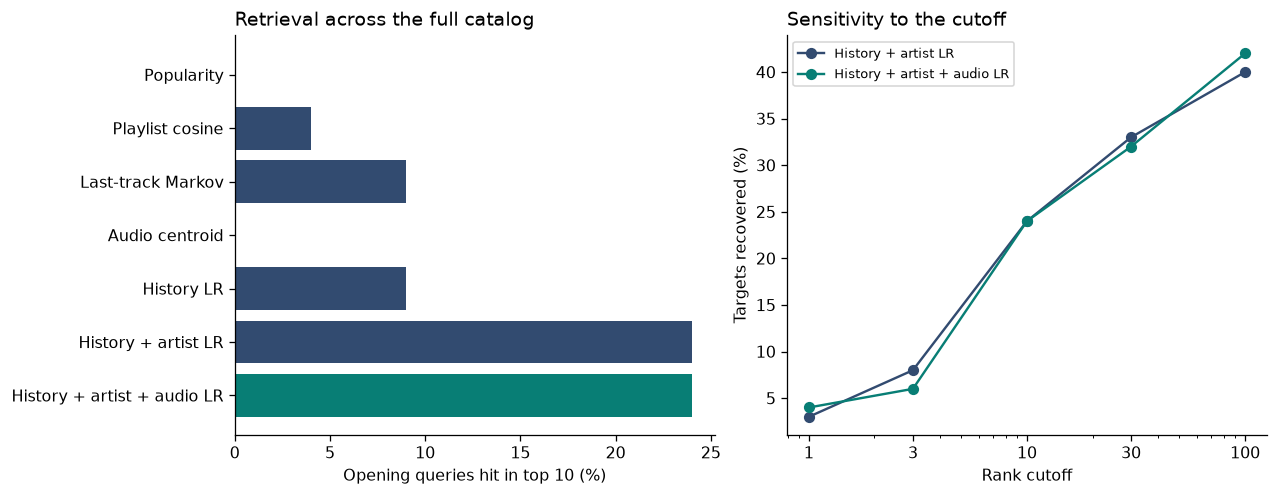

In [9]:
rows = []
for label, mask in [('Unseen',opening.support==0),('Seen',opening.support>0)]:
    subset = opening.loc[mask]
    for m in ['Playlist cosine','Audio centroid',ART,FULL]:
        rows.append({'Target history':label,'Model':m,'Queries':len(subset),
                     'Hits':int((subset[m]<=10).sum()),**metrics(subset[m])})
slices = pd.DataFrame(rows)
display(slices.set_index(['Target history','Model']))
fig,axs = plt.subplots(1,2,figsize=(11,4.2),layout='constrained')
axs[0].barh(model_order,100*scorecard.loc[model_order,'HR@10'],color=[BLUE]*6+[TEAL])
axs[0].invert_yaxis()
axs[0].set(xlabel='Opening queries hit in top 10 (%)',title='Retrieval across the full catalog')
for m,color in [(ART,BLUE),(FULL,TEAL)]:
    rates = [(opening[m]<=k).mean() for k in [1,3,10,30,100]]
    axs[1].plot([1,3,10,30,100],100*np.array(rates),marker='o',label=m,color=color)
axs[1].set_xscale('log')
axs[1].set_xticks([1,3,10,30,100],labels=['1','3','10','30','100'])
axs[1].set(xlabel='Rank cutoff',ylabel='Targets recovered (%)',title='Sensitivity to the cutoff')
axs[1].legend(fontsize=8)
plt.show()

### Paired uncertainty and robustness

Resample complete test playlists with replacement 10,000 times. For the primary endpoint each playlist contributes one paired hit difference, measured on the very same target. The percentile interval captures variation across these test playlists conditional on this sample, split and fitted models. With very few discordant hits, even a bootstrap interval can be unstable or collapse. Report the actual counts of improved and lost top-ten hits alongside it.

Two additional checks use the frozen models. The first evaluates non-overlapping windows throughout each playlist and averages within playlist before averaging across playlists, preserving equal influence. The second randomly permutes only the five visible songs while preserving the true sixth song. This tests reliance on last-song identity. The centroid and co-occurrence baselines depend only on the set of seeds.

In [10]:
def paired_summary(a,b):
    delta = np.asarray(a,float)-np.asarray(b,float)
    boot = np.random.default_rng(2026).choice(delta,(10000,len(delta)),replace=True).mean(axis=1)
    return (delta.mean(),*np.quantile(boot,[.025,.975]))

ha,hb = opening[FULL].le(10),opening[ART].le(10)
d,lo,hi = paired_summary(ha,hb)
wins,losses = int((ha & ~hb).sum()),int((~ha & hb).sum())
report(f"**Primary audio comparison.** The change in opening Hit Rate@10 is **{100*d:+.1f} percentage points** (paired 95% bootstrap interval **{100*lo:+.1f} to {100*hi:+.1f}**). The models disagreed on **{wins+losses}** top-ten outcomes. Audio gained **{wins}** and lost **{losses}**. " +
       ("This sample does not resolve a reliable direction of change." if lo<=0<=hi else "The interval excludes zero on this fixed split. External playlists would test whether the difference generalizes."))
per_playlist = results[model_order].le(10).groupby(results.pid).mean()
all_d,all_lo,all_hi = paired_summary(per_playlist[FULL],per_playlist[ART])
report(f"**Across playlist positions.** {len(results):,} non-overlapping windows in {len(per_playlist)} playlists give an audio increment of **{100*all_d:+.2f} points** (playlist-bootstrap interval **{100*all_lo:+.2f} to {100*all_hi:+.2f}**). These windows reuse the same test playlists and include the opening queries.")
shuffle_rng = np.random.default_rng(19)
sr = {m:[] for m in model_order}
for pid,k,q,t in windows(test,openings=True):
    shuffled_q = shuffle_rng.permutation(q)
    xs = design(ref,shuffled_q,items)
    # Order-invariant scores are mathematically unchanged. Reuse canonical sums
    # for these columns to prevent machine-rounding differences in tied scores.
    base = design(ref,q,items)
    assert np.allclose(xs[:,[0,1,4,5]],base[:,[0,1,4,5]])
    xs[:,[0,1,4,5]]=base[:,[0,1,4,5]]
    for m,(s,b) in score_models(xs).items():
        sr[m].append(rank_of(s,t,b))
robust = pd.DataFrame({'Opening HR@10':scorecard['HR@10'],
                       'Shuffled opening HR@10':[metrics(sr[m])['HR@10'] for m in model_order],
                       'All-window HR@10 (playlist mean)':per_playlist.mean()})
assert np.array_equal(sr['Playlist cosine'],opening['Playlist cosine'])
assert np.array_equal(sr['Audio centroid'],opening['Audio centroid'])
display(robust)

**Primary audio comparison.** The change in opening Hit Rate@10 is **+0.0 percentage points** (paired 95% bootstrap interval **-3.0 to +3.0**). The models disagreed on **2** top-ten outcomes. Audio gained **1** and lost **1**. This sample does not resolve a reliable direction of change.

**Across playlist positions.** 1,080 non-overlapping windows in 100 playlists give an audio increment of **+0.18 points** (playlist-bootstrap interval **-1.32 to +1.39**). These windows reuse the same test playlists and include the opening queries.

,Opening HR@10,Shuffled opening HR@10,All-window HR@10 (playlist mean)
Popularity,0.0000,0.0000,0.0030
Playlist cosine,0.0400,0.0400,0.0183
Last-track Markov,0.0900,0.0800,0.0340
Audio centroid,0.0000,0.0000,0.0018
History LR,0.0900,0.0800,0.0395
History + artist LR,0.2400,0.1800,0.1712
History + artist + audio LR,0.2400,0.1800,0.1729


### Where the top-ten hits come from

These exploratory diagnostics use the already frozen scores. The album comparison identifies a common shortcut in curated playlists. The simple artist rule prioritizes every recording by the fifth track's artist and breaks those ties by training popularity. The near-duplicate audit compares each entire test playlist with the closest training playlist using set Jaccard similarity. The test suffix is used here only to characterize overlap after scoring. Finally, the tie audit replaces deterministic tie-breaking by its exact expected hit probability when equally scored tracks are randomly ordered.

In [11]:
album = catalog.album_uri.to_numpy()
opening_detail = opening.copy()
opening_detail['Same album as fifth'] = [
    album[int(t)] == album[lists[int(p)][4]] for p,t in zip(opening.pid,opening.target)]
opening_detail['Target repeats a seed'] = [t in lists[p][:5] for p,t in zip(opening.pid,opening.target)]
train_sets = [set(lists[p]) for p in train]
def closest_jaccard(s):
    query = set(s)
    return max(len(query & refset)/len(query | refset) for refset in train_sets)
train_six = {tuple(lists[p][i:i+6]) for p in train for i in range(len(lists[p])-5)}
opening_detail['Opening seen verbatim'] = [tuple(lists[p][:6]) in train_six for p in opening.pid]
overlap = np.array([closest_jaccard(lists[p]) for p in opening.pid])
tie_audit = {ART:[],FULL:[]}
artist_ranks = []
for pid,k,q,t in windows(test,openings=True):
    x = design(ref,q,items)
    artist_ranks.append(rank_of((artist==artist[q[-1]]).astype(float),t,ref['n']))
    for name in tie_audit:
        w = weights[name]
        scores = x[:,:len(w)] @ w
        ahead = np.count_nonzero(scores>scores[t])
        tied = np.count_nonzero(scores==scores[t])
        tie_audit[name].append(np.clip((10-ahead)/tied,0,1))
audit_rows = []
for label,mask in [('Same album as fifth',opening_detail['Same album as fifth']),
                   ('Different album',~opening_detail['Same album as fifth']),
                   ('No verbatim training opening',~opening_detail['Opening seen verbatim'])]:
    audit_rows.append({'Slice':label,'Queries':int(mask.sum()),
                       'Artist rule HR@10':np.mean(np.array(artist_ranks)[mask]<=10),
                       'History + artist HR@10':hb[mask].mean(),'Full HR@10':ha[mask].mean()})
display(pd.DataFrame(audit_rows).set_index('Slice'))
report(f"The last-artist rule alone hits **{sum(np.array(artist_ranks)<=10)} / {len(opening)}** openings. Exact six-track openings repeat in training for **{opening_detail['Opening seen verbatim'].sum()}** test playlists. Maximum train–test Jaccard across pairs is **{overlap.max():.2f}**, with **{sum(overlap>=.8)}** test playlists reaching 0.80. **{opening_detail['Target repeats a seed'].sum()}** opening targets repeat a visible seed song. The overlap audit covers this sample and cannot identify shared curators.")
report(f"Averaging over tied positions gives expected opening Hit Rate@10 of **{np.mean(tie_audit[ART]):.2%}** with history and artist and **{np.mean(tie_audit[FULL]):.2%}** with audio added. Tie handling is especially relevant to artist-only matches for tracks lacking playlist history.")

,Queries,Artist rule HR@10,History + artist HR@10,Full HR@10
Slice,,,,
Same album as fifth,14,0.7143,0.6429,0.6429
Different album,86,0.1512,0.1744,0.1744
No verbatim training opening,100,0.2300,0.2400,0.2400


The last-artist rule alone hits **23 / 100** openings. Exact six-track openings repeat in training for **0** test playlists. Maximum train–test Jaccard across pairs is **0.26**, with **0** test playlists reaching 0.80. **0** opening targets repeat a visible seed song. The overlap audit covers this sample and cannot identify shared curators.

Averaging over tied positions gives expected opening Hit Rate@10 of **23.24%** with history and artist and **24.00%** with audio added. Tie handling is especially relevant to artist-only matches for tracks lacking playlist history.

### Inspecting a recommendation

Select the lowest-ID test opening whose target has no training appearances. This selection depends on history availability and playlist ID alone. The example shows what the model ranks highly, how far away the actual sixth song lands, and whether matching the preceding artist explains the ranking. Examples illustrate individual behavior. The aggregate tables give the evidence about general performance.

In [12]:
case = opening[opening.support==0].sort_values('pid').iloc[0]
q = lists[int(case.pid)][:5]
t = int(case.target)
x = design(ref,q,items)
scores = x @ weights[FULL]
top = np.lexsort((tie_order,-scores))[:5]
display(pd.DataFrame({'Position':[1,2,3,4,5,6], 'Role':['Seed']*5+['Target'],
                      'Song':tracks[np.r_[q,t]], 'Artist':artists[np.r_[q,t]]}).set_index('Position'))
display(pd.DataFrame({'Rank':np.arange(1,6),'Recommendation':tracks[top],'Artist':artists[top],
                      'Training playlists':freq[top], 'Same last artist':artist[top]==artist[q[-1]]}).set_index('Rank'))
report(f"Playlist **{int(case.pid)}** places *{tracks[t]}* sixth. Its full-model rank is **{int(case[FULL]):,}** of {N:,}. Of the model's top five, **{sum(artist[top]==artist[q[-1]])}** share the preceding artist.")

,Role,Song,Artist
Position,,,
1,Seed,Better,Lil Yachty
2,Seed,Young,The Chainsmokers
3,Seed,D Rose,Lil Pump
4,Seed,beibs in the trap,Travis Scott
5,Seed,Good For It,NAV
6,Target,Call Me,NAV


,Recommendation,Artist,Training playlists,Same last artist
Rank,,,,
1,Up,NAV,4,True
2,Myself,NAV,3,True
3,beibs in the trap,Travis Scott,8,False
4,NAV,NAV,1,True
5,A$AP Ferg,NAV,1,True


Playlist **25** places *Call Me* sixth. Its full-model rank is **13** of 36,203. Of the model's top five, **4** share the preceding artist.

<a id="part-5"></a>

## 5 · Related work, findings, and limits

Chen et al. evaluated automatic playlist continuation on the Million Playlist Dataset with multiple seed conditions and a set of hidden tracks. Our experiment uses one observed successor, a smaller catalog and top-ten retrieval. Their R-precision, NDCG, and clicks answer a broader playlist-completion question. Several musically reasonable continuations can receive zero credit in our exact-track evaluation. [Chen et al., RecSys 2018](https://research.atspotify.com/publications/recsys-challenge-2018-automatic-music-playlist-continuation)

Vall et al. studied sparse and out-of-set recommendations using audio, social tags and listening logs. They reported benefits for rare tracks under playlist-continuation recall at larger cutoffs. We test whether a small set of Spotify audio descriptors adds predictive value after holding historical and artist features constant. The difference in features, target and cutoff makes the direction of the effect a more meaningful comparison than raw scores. [Vall et al., 2017](https://arxiv.org/abs/1705.08283)

A separate investigation by Vall et al. studied song context and order on hand-curated playlists. Our within-prefix permutation keeps the same five songs while altering their order. The Markov baseline uses the final song alone. The full ranker can respond through the last artist, last-track audio and observed transitions. Our shuffle therefore measures those mechanisms together. [Vall et al., 2018](https://arxiv.org/abs/1807.04690)

In [13]:
cold = opening.support.eq(0)
warm = ~cold
best = scorecard['HR@10'].max()
best_names = ', '.join(scorecard.index[scorecard['HR@10'].eq(best)])
delta_order = robust.loc[FULL,'Opening HR@10']-robust.loc[FULL,'Shuffled opening HR@10']
report(f"**What this experiment establishes.** {best_names} achieved the highest opening Hit Rate@10 ({best:.1%}). Adding audio to the history-and-artist ranker changed its unseen-target hits from **{int(hb[cold].sum())} to {int(ha[cold].sum())}** across {cold.sum()} queries and seen-target hits from **{int(hb[warm].sum())} to {int(ha[warm].sum())}** across {warm.sum()}. The full model's original-minus-shuffled opening difference was **{100*delta_order:+.1f} points**. These counts describe how much evidence this slice supplies for the content and sequence hypotheses.")

**What this experiment establishes.** History + artist LR, History + artist + audio LR achieved the highest opening Hit Rate@10 (24.0%). Adding audio to the history-and-artist ranker changed its unseen-target hits from **8 to 8** across 51 queries and seen-target hits from **16 to 16** across 49. The full model's original-minus-shuffled opening difference was **+6.0 points**. These counts describe how much evidence this slice supplies for the content and sequence hypotheses.

**What to take away.** The 51 unseen targets give the sharpest distinction between *finding a plausible neighborhood* and *identifying the exact recording*. Adding audio improves their median rank from 31,751 to 9,610, but both models retrieve eight in the top ten. On the 49 seen targets, median rank moves from 129 to 200, and the number of hits stays at 16. These results provide narrower support for audio than the rare-song gains in Vall et al. Their features include tags and listening behavior, and their evaluation rewards retrieval deeper in the list.

**Which model would we use?** For a ten-slot list on a comparable catalog, the history-and-artist model is the defensible choice from validation. The simpler last-artist rule is a competitive fallback, particularly on album runs. Fourteen test openings continue the preceding album. The full model retrieves nine of those fourteen, versus fifteen of the other 86. On a broader shortlist, audio merits further study because its modest changes at ranks 30 and 100 go in different directions. A second independent slice would give a fair test of that new hypothesis.

### What limits the claim, and how to address it

| Concern | Consequence in this experiment | Defensible follow-up |
|---|---|---|
| Sparse pair history | A first-order transition count gives many candidates a tie. Popularity resolves those ties. | Report how many true transitions were observed, and compare an artist-level transition fallback on a new validation split. |
| Catalog availability | Catalog membership and static audio come from one historical snapshot. Track release dates and real-time availability are unknown. | Repeat on a dated catalog and restrict eligible tracks to those available at prediction time. |
| Negative labels and competing songs | A different sixth song may also fit. Uniform training negatives are often easy. | On a fresh validation set, compare artist-matched negatives. To study suitability, obtain human judgments or multiple relevant continuations. |
| Sampling and dependence | One slice, shared artists/tracks, and potentially related playlists limit generalization. Creator IDs are unavailable here. | Replicate on independent slices and use creator-disjoint splits when creator identifiers are available. Bootstrap intervals here cover only playlist sampling on the fixed split. |
| Artist and album runs | Adjacent tracks can share an artist or reproduce album order. Audio gain can depend on these runs. | Keep the matched artist ablation above. Compare the same-album and different-album groups reported above. A separate listening log is needed for claims about listening behavior. |
| Missing deployment metadata | The audio ranker assumes every candidate has descriptors. | For missing metadata at serving time, use the history-and-artist ranker, then popularity if seed evidence is unavailable. Report the fraction requiring fallback. |

**Reproduction checklist.** The input hash, package versions, playlist split seed, cross-fitting scheme, candidate policy, tie order, model grid and bootstrap seed appear above. All displayed figures and tables are embedded in the HTML. For the recorded walkthrough, trace one six-song example, show the train-only reference construction, and explain the paired comparison and its uncertainty.